In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

if not csv_files:
    raise FileNotFoundError(
        "CSV file পাওয়া যায়নি। Kaggle Notebook-এ Add Input দিয়ে dataset যোগ করো।"
    )

print("Available CSV files:")
for i, file in enumerate(csv_files):
    print(i, file)

# প্রথম CSV file load করা হচ্ছে
df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Available CSV files:
0 /kaggle/input/datasets/fatemaaktherpromy/unemployment-analysis-with-python-codealpha/Unemployment_Rate_upto_11_2020.csv
1 /kaggle/input/datasets/fatemaaktherpromy/unemployment-analysis-with-python-codealpha/Unemployment in India.csv

Dataset loaded successfully!
Dataset shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


In [5]:
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 9 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   267 non-null    object 
 1   Date                                     267 non-null    object 
 2   Frequency                                267 non-null    object 
 3   Estimated Unemployment Rate (%)          267 non-null    float64
 4   Estimated Employed                       267 non-null    int64  
 5   Estimated Labour Participation Rate (%)  267 non-null    float64
 6   Region.1                                 267 non-null    object 
 7   longitude                                267 non-null   

In [6]:
# Duplicate rows বাদ দেওয়া
df = df.drop_duplicates().copy()

# Text columns পরিষ্কার করা
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Date column থাকলে date format-এ পরিবর্তন
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(
        df["Date"], errors="coerce", dayfirst=True
    )

# পরিচিত numeric columns-কে number-এ পরিবর্তন
numeric_candidates = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)",
    "Unemployment Rate",
    "Unemployment Rate (%)"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Cleaning completed!")
print("Updated shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Cleaning completed!
Updated shape: (267, 9)

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64


In [7]:
possible_rate_columns = [
    "Estimated Unemployment Rate (%)",
    "Unemployment Rate (%)",
    "Unemployment Rate"
]

RATE_COL = next(
    (col for col in possible_rate_columns if col in df.columns),
    None
)

if RATE_COL is None:
    raise ValueError(
        "Unemployment rate column পাওয়া যায়নি। "
        "df.columns.tolist() দেখে সঠিক column name নির্ধারণ করো।"
    )

print("Unemployment rate column:", RATE_COL)
display(df.describe(include="all"))

Unemployment rate column: Estimated Unemployment Rate (%)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
count,267,267,267,267.000000,2.670000e+02,267.000000,267,267.000000,267.000000
unique,27,NaN,1,NaN,NaN,NaN,5,NaN,NaN
top,Andhra Pradesh,NaN,M,NaN,NaN,NaN,North,NaN,NaN
freq,10,NaN,267,NaN,NaN,NaN,79,NaN,NaN
mean,NaN,2020-06-16 09:15:30.337078528,NaN,12.236929,1.396211e+07,41.681573,NaN,22.826048,80.532425
min,NaN,2020-01-31 00:00:00,NaN,0.500000,1.175420e+05,16.770000,NaN,10.850500,71.192400
25%,NaN,2020-03-31 00:00:00,NaN,4.845000,2.838930e+06,37.265000,NaN,18.112400,76.085600
50%,NaN,2020-06-30 00:00:00,NaN,9.650000,9.732417e+06,40.390000,NaN,23.610200,79.019300
75%,NaN,2020-08-31 00:00:00,NaN,16.755000,2.187869e+07,44.055000,NaN,27.278400,85.279900
max,NaN,2020-10-31 00:00:00,NaN,75.850000,5.943376e+07,69.690000,NaN,33.778200,92.937600


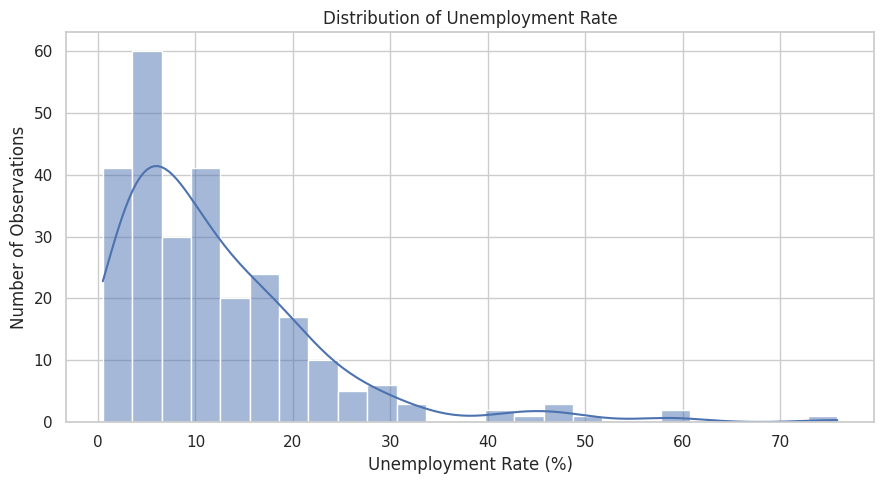

In [8]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x=RATE_COL,
    bins=25,
    kde=True
)

plt.title("Distribution of Unemployment Rate")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

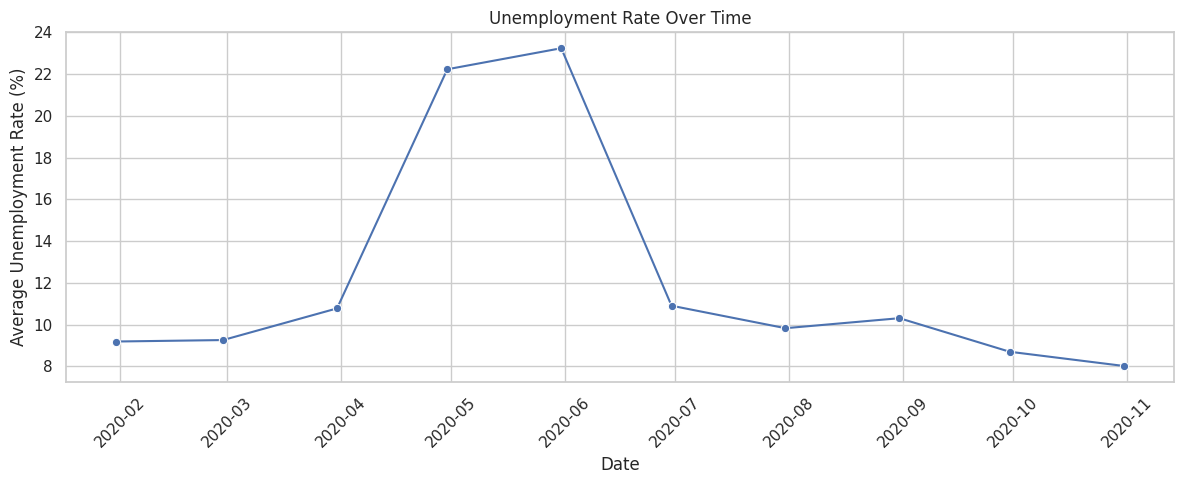

In [9]:
if "Date" in df.columns:
    trend_df = df.dropna(subset=["Date", RATE_COL]).copy()
    trend_df = trend_df.sort_values("Date")

    # প্রতিটি date-এর গড় unemployment rate
    time_trend = (
        trend_df.groupby("Date", as_index=False)[RATE_COL]
        .mean()
    )

    plt.figure(figsize=(12, 5))
    sns.lineplot(
        data=time_trend,
        x="Date",
        y=RATE_COL,
        marker="o"
    )

    plt.title("Unemployment Rate Over Time")
    plt.xlabel("Date")
    plt.ylabel("Average Unemployment Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Date column নেই। Time-trend graph তৈরি করা সম্ভব নয়।")

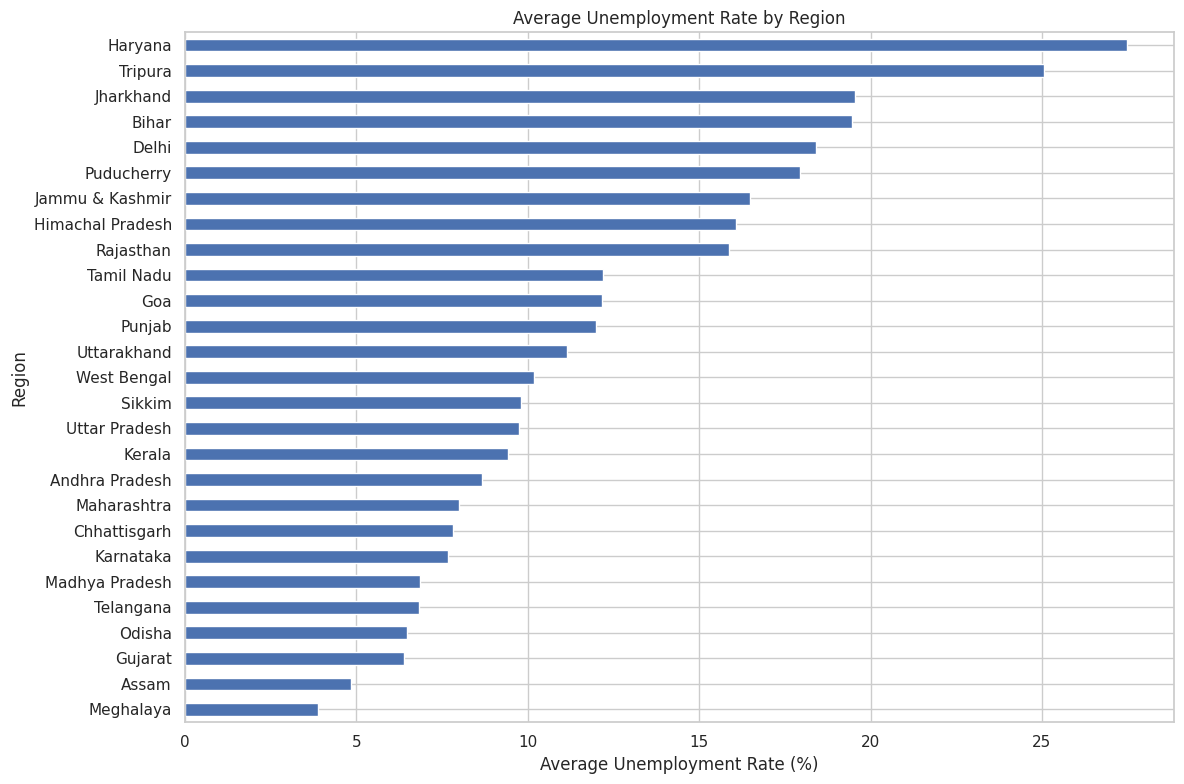

Highest average unemployment rate:
Region
Haryana      27.477
Tripura      25.055
Jharkhand    19.539
Bihar        19.471
Delhi        18.414
Name: Estimated Unemployment Rate (%), dtype: float64

Lowest average unemployment rate:
Region
Telangana    6.833
Odisha       6.462
Gujarat      6.376
Assam        4.856
Meghalaya    3.866
Name: Estimated Unemployment Rate (%), dtype: float64


In [10]:
if "Region" in df.columns:
    region_rates = (
        df.groupby("Region")[RATE_COL]
        .mean()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(12, 8))
    region_rates.sort_values().plot(kind="barh")

    plt.title("Average Unemployment Rate by Region")
    plt.xlabel("Average Unemployment Rate (%)")
    plt.ylabel("Region")
    plt.tight_layout()
    plt.show()

    print("Highest average unemployment rate:")
    print(region_rates.head(5))

    print("\nLowest average unemployment rate:")
    print(region_rates.tail(5))
else:
    print("Region column পাওয়া যায়নি।")

,mean,median,count
Period,,,
Before COVID-19,9.23,6.66,52
COVID-19 period onward,12.96,10.11,215


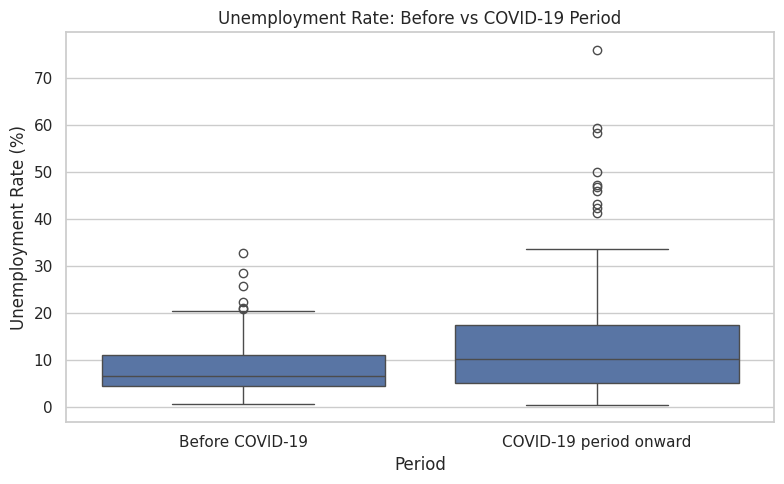

In [11]:
if "Date" in df.columns:
    covid_df = df.dropna(subset=["Date", RATE_COL]).copy()

    covid_df["Period"] = np.where(
        covid_df["Date"] < pd.Timestamp("2020-03-01"),
        "Before COVID-19",
        "COVID-19 period onward"
    )

    covid_summary = (
        covid_df.groupby("Period")[RATE_COL]
        .agg(["mean", "median", "count"])
        .round(2)
    )

    display(covid_summary)

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=covid_df,
        x="Period",
        y=RATE_COL
    )

    plt.title("Unemployment Rate: Before vs COVID-19 Period")
    plt.xlabel("Period")
    plt.ylabel("Unemployment Rate (%)")
    plt.tight_layout()
    plt.show()
else:
    print("COVID-19 comparison-এর জন্য Date column প্রয়োজন।")

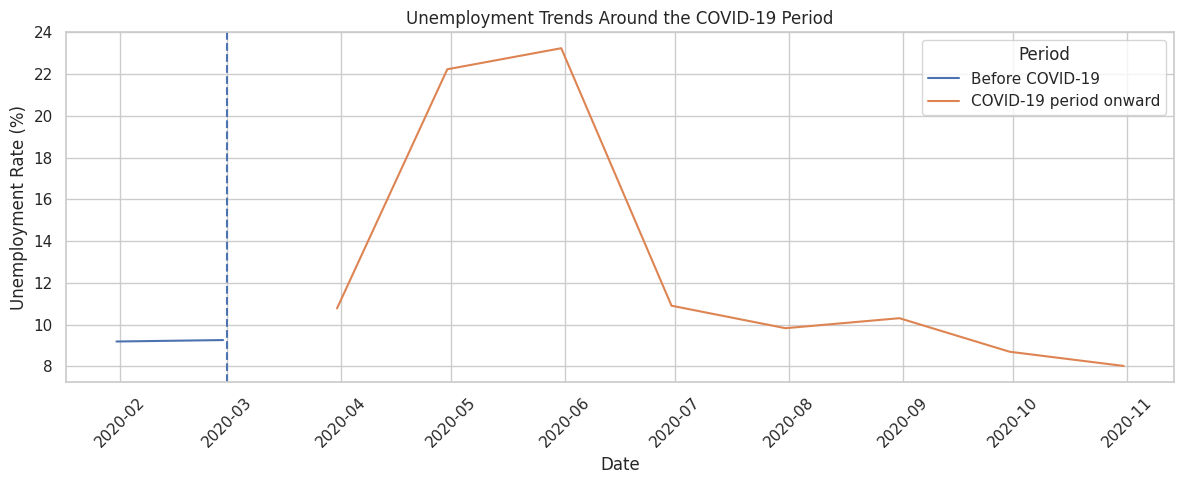

In [12]:
if "Date" in df.columns:
    plt.figure(figsize=(12, 5))

    sns.lineplot(
        data=covid_df,
        x="Date",
        y=RATE_COL,
        hue="Period",
        errorbar=None
    )

    plt.axvline(
        pd.Timestamp("2020-03-01"),
        linestyle="--",
        label="March 2020"
    )

    plt.title("Unemployment Trends Around the COVID-19 Period")
    plt.xlabel("Date")
    plt.ylabel("Unemployment Rate (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

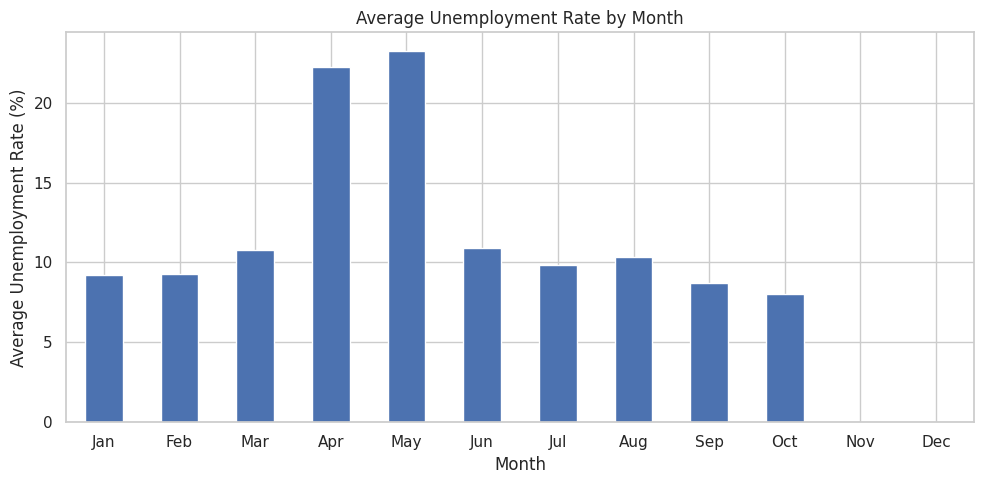

Monthly average unemployment rate:


Month
1      9.196538
2      9.266154
3     10.782593
4     22.236154
5     23.244444
6     10.911111
7      9.834444
8     10.313333
9      8.705926
10     8.026296
11          NaN
12          NaN
Name: Average Unemployment Rate (%), dtype: float64

In [13]:
if "Date" in df.columns:
    seasonal_df = df.dropna(subset=["Date", RATE_COL]).copy()
    seasonal_df["Month"] = seasonal_df["Date"].dt.month

    monthly_rates = (
        seasonal_df.groupby("Month")[RATE_COL]
        .mean()
        .reindex(range(1, 13))
    )

    month_names = [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]

    plt.figure(figsize=(10, 5))
    monthly_rates.plot(kind="bar")

    plt.title("Average Unemployment Rate by Month")
    plt.xlabel("Month")
    plt.ylabel("Average Unemployment Rate (%)")
    plt.xticks(
        ticks=range(12),
        labels=month_names,
        rotation=0
    )
    plt.tight_layout()
    plt.show()

    print("Monthly average unemployment rate:")
    display(monthly_rates.rename("Average Unemployment Rate (%)"))
else:
    print("Seasonal analysis-এর জন্য Date column প্রয়োজন।")

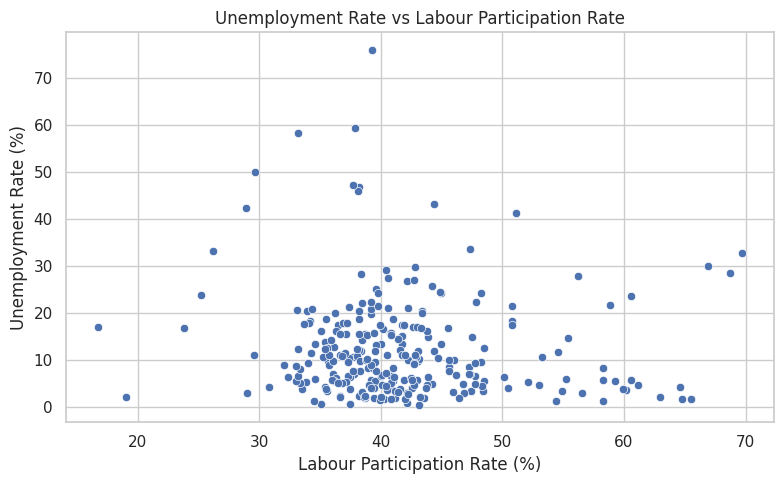

Correlation: -0.074


In [14]:
labour_col = "Estimated Labour Participation Rate (%)"

if labour_col in df.columns:
    relationship_df = df[[RATE_COL, labour_col]].dropna()

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=relationship_df,
        x=labour_col,
        y=RATE_COL
    )

    plt.title("Unemployment Rate vs Labour Participation Rate")
    plt.xlabel("Labour Participation Rate (%)")
    plt.ylabel("Unemployment Rate (%)")
    plt.tight_layout()
    plt.show()

    print(
        "Correlation:",
        round(relationship_df[RATE_COL].corr(
            relationship_df[labour_col]
        ), 3)
    )
else:
    print("Labour participation rate column পাওয়া যায়নি।")

In [15]:
print("=" * 55)
print("UNEMPLOYMENT ANALYSIS: KEY FINDINGS")
print("=" * 55)

print("\n1. Dataset overview")
print("Total observations:", len(df))
print("Unemployment rate column:", RATE_COL)
print("Average unemployment rate:", round(df[RATE_COL].mean(), 2), "%")
print("Median unemployment rate:", round(df[RATE_COL].median(), 2), "%")
print("Minimum unemployment rate:", round(df[RATE_COL].min(), 2), "%")
print("Maximum unemployment rate:", round(df[RATE_COL].max(), 2), "%")

if "Date" in df.columns:
    valid_dates = df["Date"].dropna()

    if not valid_dates.empty:
        print("\n2. Date coverage")
        print("Start date:", valid_dates.min().date())
        print("End date:", valid_dates.max().date())

if "Region" in df.columns:
    region_avg = df.groupby("Region")[RATE_COL].mean().dropna()

    if not region_avg.empty:
        print("\n3. Regional comparison")
        print("Highest average:", region_avg.idxmax(),
              "-", round(region_avg.max(), 2), "%")
        print("Lowest average:", region_avg.idxmin(),
              "-", round(region_avg.min(), 2), "%")

if "Date" in df.columns:
    valid_covid = df.dropna(subset=["Date", RATE_COL]).copy()

    before = valid_covid.loc[
        valid_covid["Date"] < "2020-03-01", RATE_COL
    ]
    during = valid_covid.loc[
        valid_covid["Date"] >= "2020-03-01", RATE_COL
    ]

    if not before.empty and not during.empty:
        difference = during.mean() - before.mean()

        print("\n4. COVID-19 period comparison")
        print("Before COVID-19 average:", round(before.mean(), 2), "%")
        print("COVID-19 period onward average:",
              round(during.mean(), 2), "%")
        print("Difference:", round(difference, 2), "percentage points")

print("\nAnalysis completed!")

UNEMPLOYMENT ANALYSIS: KEY FINDINGS

1. Dataset overview
Total observations: 267
Unemployment rate column: Estimated Unemployment Rate (%)
Average unemployment rate: 12.24 %
Median unemployment rate: 9.65 %
Minimum unemployment rate: 0.5 %
Maximum unemployment rate: 75.85 %

2. Date coverage
Start date: 2020-01-31
End date: 2020-10-31

3. Regional comparison
Highest average: Haryana - 27.48 %
Lowest average: Meghalaya - 3.87 %

4. COVID-19 period comparison
Before COVID-19 average: 9.23 %
COVID-19 period onward average: 12.96 %
Difference: 3.73 percentage points

Analysis completed!


In [16]:
df.to_csv("cleaned_unemployment_data.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
